In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision.datasets import MNIST

RANDOM_STATE = 42

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)

# Load MNIST dataset
train_dataset = MNIST(
    root="./data",
    train=True,
    download=True,
)

test_dataset = MNIST(
    root="./data",
    train=False,
    download=True,
)

# Combine training and test datasets
X = np.concatenate(
    [
        train_dataset.data.numpy(),
        test_dataset.data.numpy(),
    ]
)

y = np.concatenate(
    [
        train_dataset.targets.numpy(),
        test_dataset.targets.numpy(),
    ]
)

# Flatten images and normalize pixel values
X = X.reshape(-1, 784).astype(np.float32) / 255.0

print(f"Dataset shape: {X.shape}")
print(f"Labels shape: {y.shape}")
print(f"Number of classes: {len(np.unique(y))}")


100.0%
100.0%
100.0%
100.0%

Dataset shape: (70000, 784)
Labels shape: (70000,)
Number of classes: 10


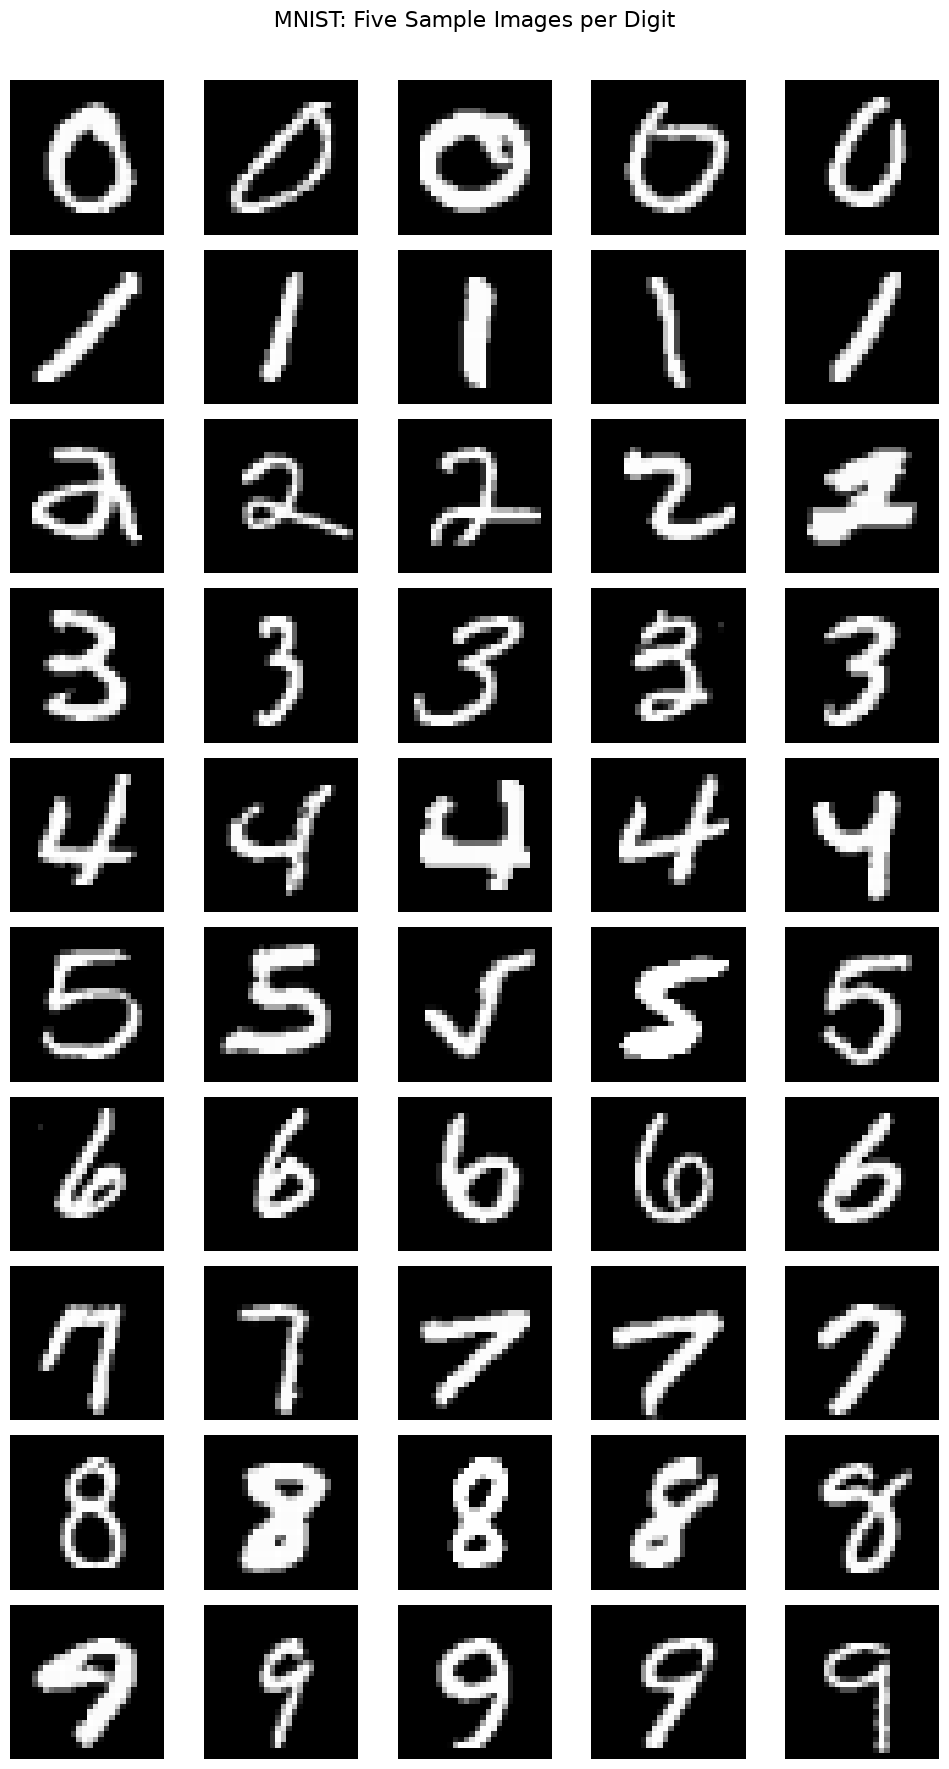

In [3]:
fig, axes = plt.subplots(
    10,
    5,
    figsize=(10, 18),
)

rng = np.random.default_rng(RANDOM_STATE)

for digit in range(10):
    indices = np.where(y == digit)[0]
    selected = rng.choice(
        indices,
        size=5,
        replace=False,
    )

    for j, idx in enumerate(selected):
        axes[digit, j].imshow(
            X[idx].reshape(28, 28),
            cmap="gray",
        )

        axes[digit, j].axis("off")

        if j == 0:
            axes[digit, j].set_ylabel(
                str(digit),
                rotation=0,
                labelpad=15,
                fontsize=12,
            )

plt.suptitle(
    "MNIST: Five Sample Images per Digit",
    fontsize=16,
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.savefig(
    FIGURES_DIR / "mnist_samples.png",
    dpi=300,
)

plt.show()

In [4]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=50,
    svd_solver="randomized",
    random_state=RANDOM_STATE,
)

X_pca = pca.fit_transform(X)

print(f"Original shape: {X.shape}")
print(f"PCA shape: {X_pca.shape}")
print(
    f"Explained variance ratio: "
    f"{pca.explained_variance_ratio_.sum():.4f}"
)

Original shape: (70000, 784)
PCA shape: (70000, 50)
Explained variance ratio: 0.8254


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.model_selection import KFold

# K-Means hyperparameter configurations
n_clusters_list = [8, 10, 12]
n_init_list = [5, 10]

cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE,
)

results = []

# Use a subset for faster cross-validation
rng = np.random.default_rng(RANDOM_STATE)
subset_indices = rng.choice(
    len(X_pca),
    size=10000,
    replace=False,
)

X_subset = X_pca[subset_indices]
y_subset = y[subset_indices]

for n_clusters in n_clusters_list:
    for n_init in n_init_list:
        fold_scores = []

        for train_idx, val_idx in cv.split(X_subset):
            X_train_cv = X_subset[train_idx]
            X_val_cv = X_subset[val_idx]

            model = KMeans(
                n_clusters=n_clusters,
                n_init=n_init,
                random_state=RANDOM_STATE,
            )

            model.fit(X_train_cv)

            val_clusters = model.predict(X_val_cv)

            score = silhouette_score(
                X_val_cv,
                val_clusters,
                sample_size=2000,
                random_state=RANDOM_STATE,
            )

            fold_scores.append(score)

        mean_score = np.mean(fold_scores)

        results.append({
            "n_clusters": n_clusters,
            "n_init": n_init,
            "silhouette_score": mean_score,
        })

        print(
            f"K={n_clusters}, "
            f"n_init={n_init}, "
            f"CV Silhouette={mean_score:.4f}"
        )

best_result = max(
    results,
    key=lambda x: x["silhouette_score"],
)

print("\nBest K-Means Configuration:")
print(best_result)

K=8, n_init=5, CV Silhouette=0.0956
K=8, n_init=10, CV Silhouette=0.0956
K=10, n_init=5, CV Silhouette=0.0807
K=10, n_init=10, CV Silhouette=0.0818
K=12, n_init=5, CV Silhouette=0.0823
K=12, n_init=10, CV Silhouette=0.0828

Best K-Means Configuration:
{'n_clusters': 8, 'n_init': 10, 'silhouette_score': np.float64(0.0956152155995369)}


In [6]:
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import KFold

# GMM hyperparameter configurations
n_components_list = [8, 10, 12]
covariance_types = ["diag", "spherical"]

cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE,
)

gmm_results = []

for n_components in n_components_list:
    for covariance_type in covariance_types:
        fold_scores = []

        for train_idx, val_idx in cv.split(X_subset):
            X_train_cv = X_subset[train_idx]
            X_val_cv = X_subset[val_idx]

            model = GaussianMixture(
                n_components=n_components,
                covariance_type=covariance_type,
                random_state=RANDOM_STATE,
                max_iter=100,
                reg_covar=1e-5,
            )

            model.fit(X_train_cv)

            # Evaluate held-out data using average log-likelihood
            score = model.score(X_val_cv)

            fold_scores.append(score)

        mean_score = np.mean(fold_scores)

        gmm_results.append({
            "n_components": n_components,
            "covariance_type": covariance_type,
            "log_likelihood": mean_score,
        })

        print(
            f"Components={n_components}, "
            f"Covariance={covariance_type}, "
            f"CV Log-Likelihood={mean_score:.4f}"
        )

best_gmm_result = max(
    gmm_results,
    key=lambda x: x["log_likelihood"],
)

print("\nBest GMM Configuration:")
print(best_gmm_result)

Components=8, Covariance=diag, CV Log-Likelihood=-52.8023
Components=8, Covariance=spherical, CV Log-Likelihood=-60.2229
Components=10, Covariance=diag, CV Log-Likelihood=-52.3776
Components=10, Covariance=spherical, CV Log-Likelihood=-59.4738
Components=12, Covariance=diag, CV Log-Likelihood=-51.8483
Components=12, Covariance=spherical, CV Log-Likelihood=-58.7422

Best GMM Configuration:
{'n_components': 12, 'covariance_type': 'diag', 'log_likelihood': np.float64(-51.848297119140625)}


In [7]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

# 1. Train best K-Means model
best_kmeans = KMeans(
    n_clusters=best_result["n_clusters"],
    n_init=best_result["n_init"],
    random_state=RANDOM_STATE,
)

kmeans_labels = best_kmeans.fit_predict(X_subset)


# 2. Train best GMM model
best_gmm = GaussianMixture(
    n_components=best_gmm_result["n_components"],
    covariance_type=best_gmm_result["covariance_type"],
    random_state=RANDOM_STATE,
    max_iter=100,
    reg_covar=1e-5,
)

gmm_labels = best_gmm.fit_predict(X_subset)


# 3. Evaluate K-Means
kmeans_silhouette = silhouette_score(
    X_subset,
    kmeans_labels,
    sample_size=2000,
    random_state=RANDOM_STATE,
)

kmeans_ari = adjusted_rand_score(
    y_subset,
    kmeans_labels,
)


# 4. Evaluate GMM
gmm_silhouette = silhouette_score(
    X_subset,
    gmm_labels,
    sample_size=2000,
    random_state=RANDOM_STATE,
)

gmm_ari = adjusted_rand_score(
    y_subset,
    gmm_labels,
)


# 5. Print comparison
print("=" * 50)
print("Clustering Model Comparison")
print("=" * 50)

print(
    f"K-Means: Silhouette={kmeans_silhouette:.4f}, "
    f"ARI={kmeans_ari:.4f}"
)

print(
    f"GMM:     Silhouette={gmm_silhouette:.4f}, "
    f"ARI={gmm_ari:.4f}"
)

Clustering Model Comparison
K-Means: Silhouette=0.0995, ARI=0.3890
GMM:     Silhouette=0.0372, ARI=0.2946


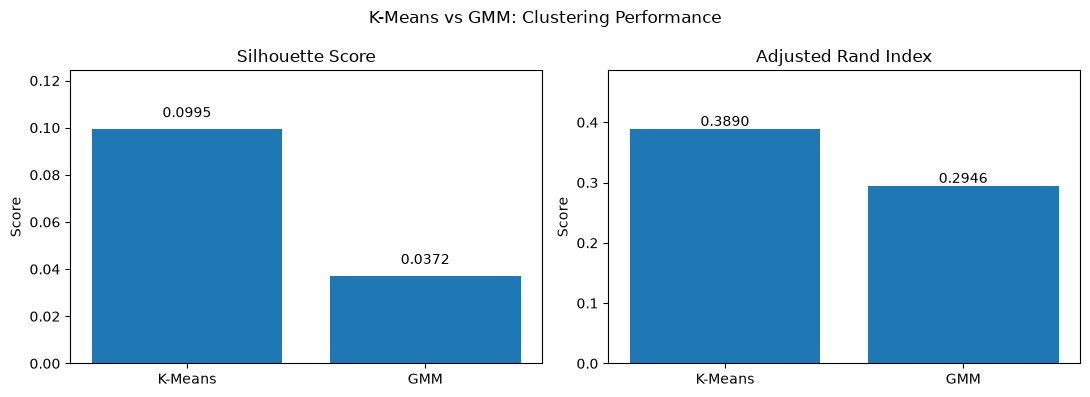

In [8]:
import matplotlib.pyplot as plt

models = ["K-Means", "GMM"]

metrics = {
    "Silhouette Score": [kmeans_silhouette, gmm_silhouette],
    "Adjusted Rand Index": [kmeans_ari, gmm_ari],
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (metric_name, values) in zip(axes, metrics.items()):
    bars = ax.bar(models, values)

    ax.set_title(metric_name)
    ax.set_ylabel("Score")
    ax.set_ylim(0, max(values) * 1.25)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.005,
            f"{value:.4f}",
            ha="center",
        )

plt.suptitle("K-Means vs GMM: Clustering Performance")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "clustering_model_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [10]:
def plot_cluster_samples(
    X_images,
    cluster_labels,
    model_name,
    filename,
    samples_per_cluster=5,
):
    unique_clusters = np.unique(cluster_labels)
    n_clusters = len(unique_clusters)

    fig, axes = plt.subplots(
        n_clusters,
        samples_per_cluster,
        figsize=(10, n_clusters * 1.8),
        squeeze=False,
    )

    rng = np.random.default_rng(RANDOM_STATE)

    for row, cluster in enumerate(unique_clusters):
        indices = np.where(cluster_labels == cluster)[0]

        selected = rng.choice(
            indices,
            size=min(samples_per_cluster, len(indices)),
            replace=False,
        )

        for col in range(samples_per_cluster):
            ax = axes[row, col]

            if col < len(selected):
                ax.imshow(
                    X_images[selected[col]].reshape(28, 28),
                    cmap="gray",
                )

            ax.axis("off")

            if col == 0:
                ax.set_ylabel(
                    f"Cluster {cluster}",
                    rotation=0,
                    labelpad=45,
                    fontsize=10,
                )

    plt.suptitle(
        f"{model_name}: Five Sample Images per Cluster",
        fontsize=15,
    )

    plt.tight_layout(rect=[0.08, 0, 1, 0.97])

    plt.savefig(
        FIGURES_DIR / filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

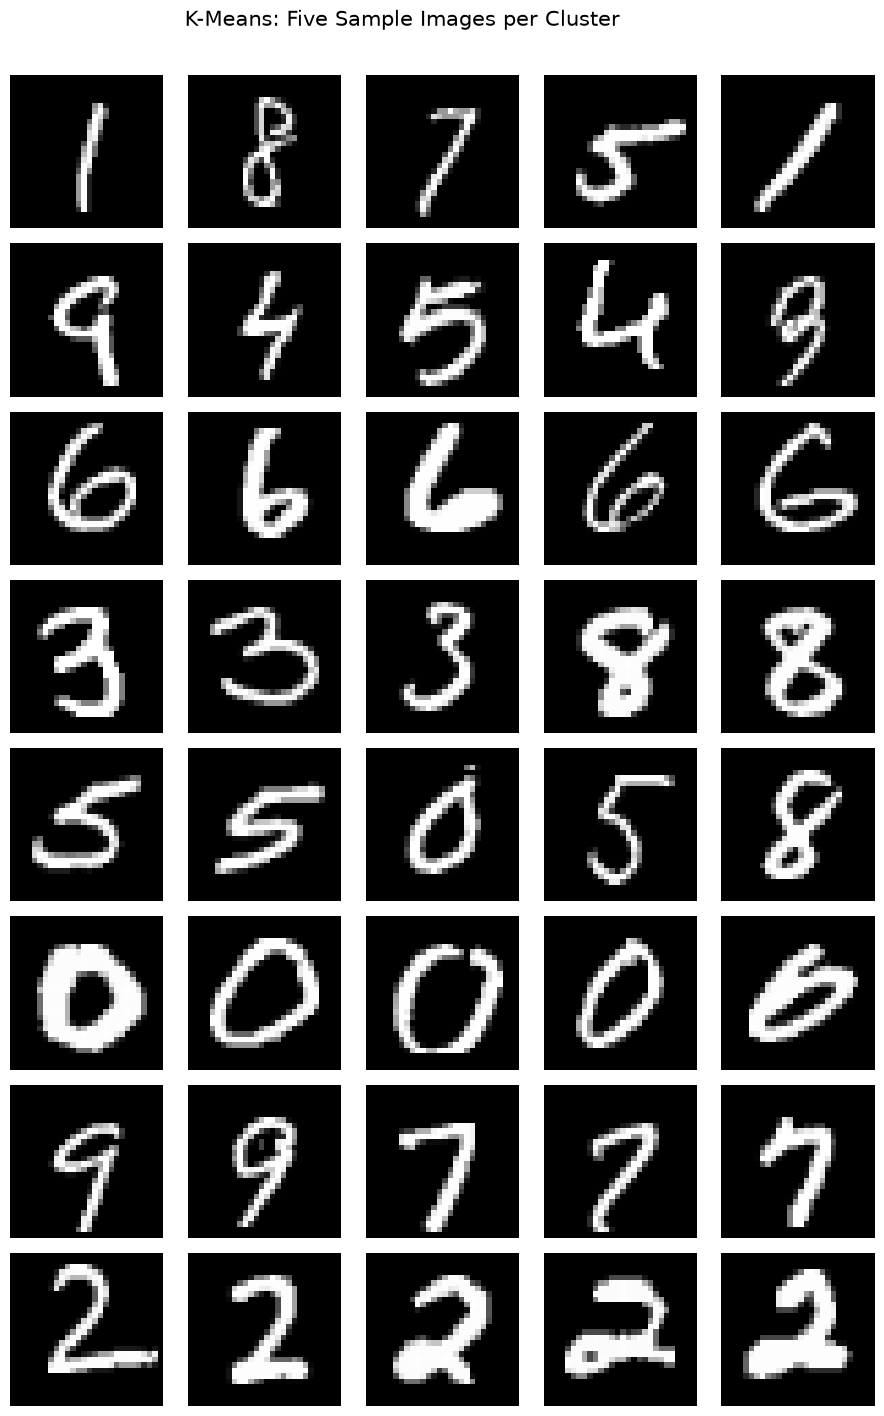

In [11]:
X_images_subset = X[subset_indices]

plot_cluster_samples(
    X_images=X_images_subset,
    cluster_labels=kmeans_labels,
    model_name="K-Means",
    filename="kmeans_cluster_samples.png",
)

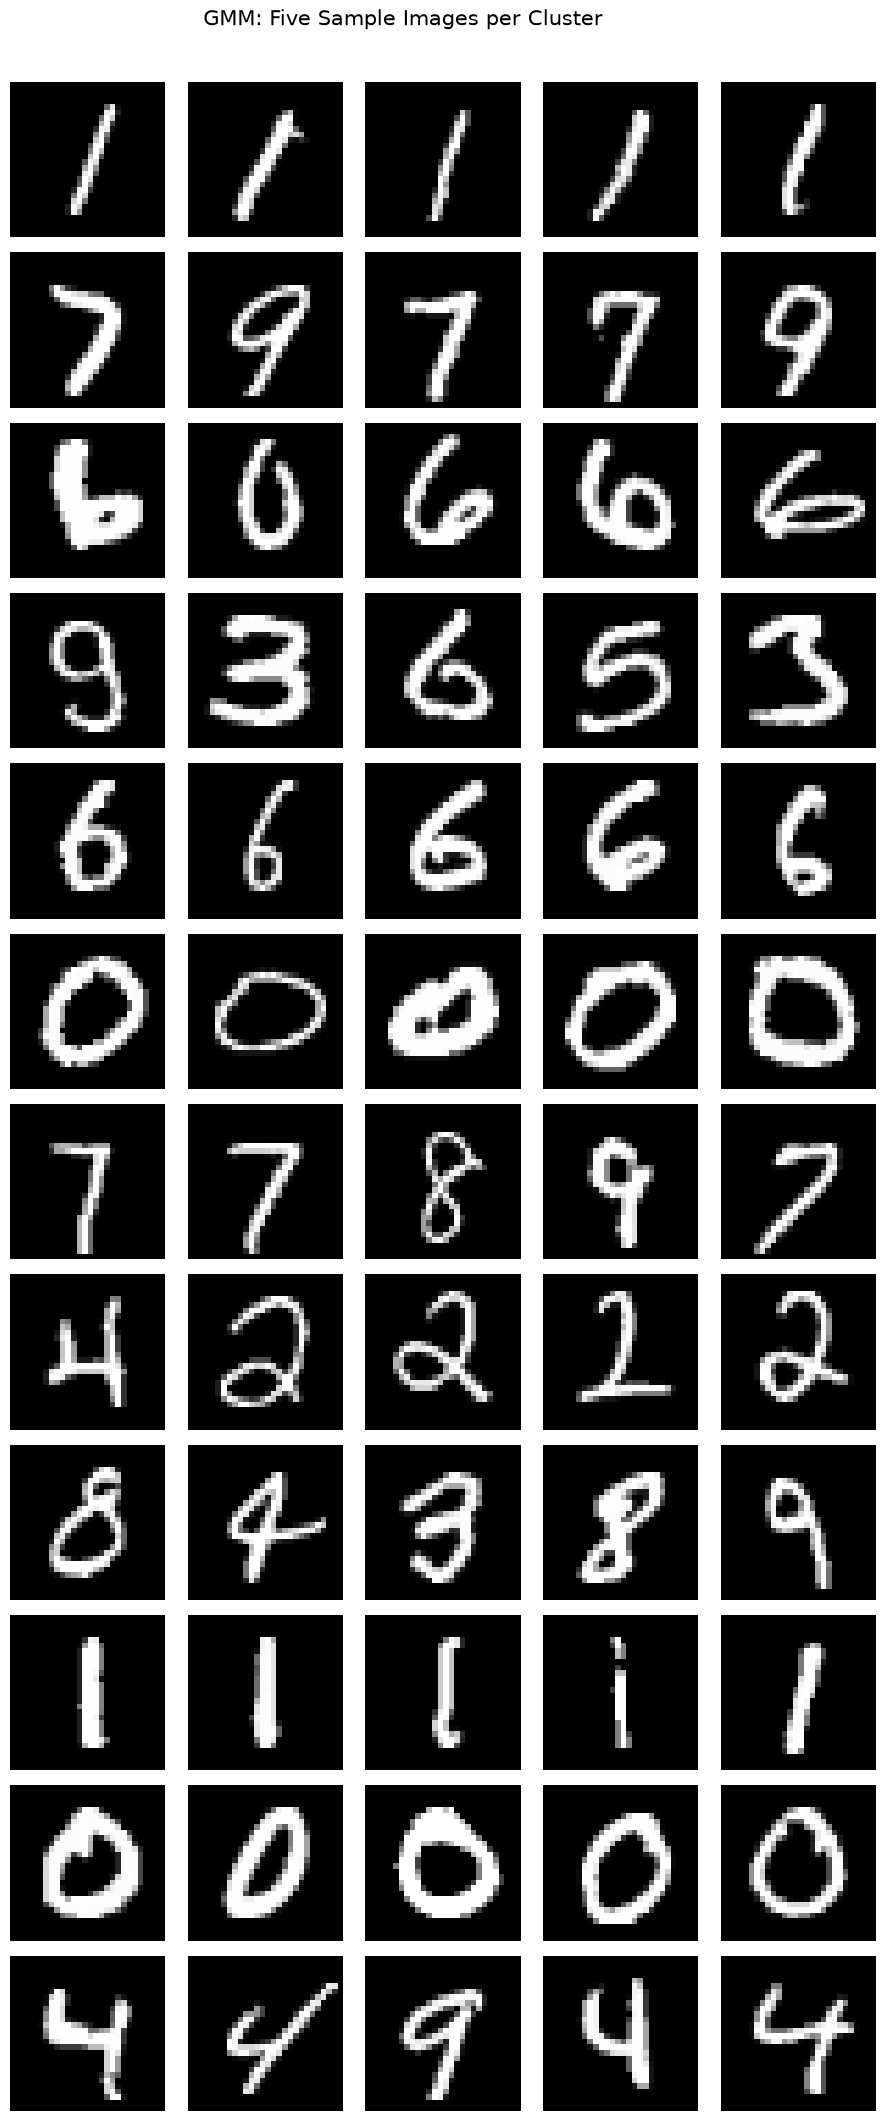

In [12]:
plot_cluster_samples(
    X_images=X_images_subset,
    cluster_labels=gmm_labels,
    model_name="GMM",
    filename="gmm_cluster_samples.png",
)